In [2]:
# ============================================
# PROJET 2 : PRÉDICTION DU DIABÈTE
# Auteur : KONATE ZANA Oumar
# Dataset : Pima Indians Diabetes
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

colonnes = ['Grossesses', 'Glucose', 'Pression', 'Epaisseur_Peau',
            'Insuline', 'IMC', 'Heredite', 'Age', 'Diabete']

df = pd.read_csv(url, names=colonnes)

print("=== DIMENSIONS ===")
print(f"{df.shape[0]} patientes × {df.shape[1]} variables")
print("\n=== 5 PREMIÈRES LIGNES ===")
print(df.head())
print("\n=== STATISTIQUES GÉNÉRALES ===")
print(df.describe().round(2))
print("\n=== RÉPARTITION DIABÉTIQUES / NON-DIABÉTIQUES ===")
print(df['Diabete'].value_counts())
print(f"\nTaux de diabète : {df['Diabete'].mean()*100:.1f}%")

=== DIMENSIONS ===
768 patientes × 9 variables

=== 5 PREMIÈRES LIGNES ===
   Grossesses  Glucose  Pression  Epaisseur_Peau  Insuline   IMC  Heredite  \
0           6      148        72              35         0  33.6     0.627   
1           1       85        66              29         0  26.6     0.351   
2           8      183        64               0         0  23.3     0.672   
3           1       89        66              23        94  28.1     0.167   
4           0      137        40              35       168  43.1     2.288   

   Age  Diabete  
0   50        1  
1   31        0  
2   32        1  
3   21        0  
4   33        1  

=== STATISTIQUES GÉNÉRALES ===
       Grossesses  Glucose  Pression  Epaisseur_Peau  Insuline     IMC  \
count      768.00   768.00    768.00          768.00    768.00  768.00   
mean         3.85   120.89     69.11           20.54     79.80   31.99   
std          3.37    31.97     19.36           15.95    115.24    7.88   
min          0.00   

=== ZÉROS IMPOSSIBLES (valeurs manquantes déguisées) ===
Glucose         :    5 zéros (0.7%)
Pression        :   35 zéros (4.6%)
Epaisseur_Peau  :  227 zéros (29.6%)
Insuline        :  374 zéros (48.7%)
IMC             :   11 zéros (1.4%)

=== VALEURS MANQUANTES APRÈS CORRECTION ===
Grossesses          0
Glucose             5
Pression           35
Epaisseur_Peau    227
Insuline          374
IMC                11
Heredite            0
Age                 0
Diabete             0
dtype: int64


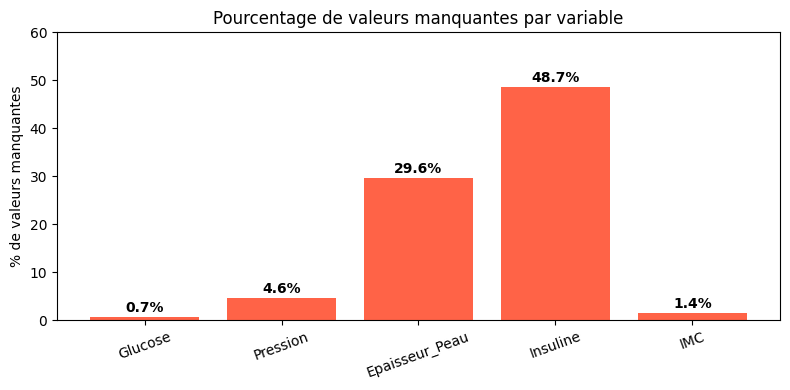


=== STATISTIQUES APRÈS NETTOYAGE ===
       Grossesses  Glucose  Pression  Epaisseur_Peau  Insuline     IMC  \
count      768.00   763.00    733.00          541.00    394.00  757.00   
mean         3.85   121.69     72.41           29.15    155.55   32.46   
std          3.37    30.54     12.38           10.48    118.78    6.92   
min          0.00    44.00     24.00            7.00     14.00   18.20   
25%          1.00    99.00     64.00           22.00     76.25   27.50   
50%          3.00   117.00     72.00           29.00    125.00   32.30   
75%          6.00   141.00     80.00           36.00    190.00   36.60   
max         17.00   199.00    122.00           99.00    846.00   67.10   

       Heredite     Age  Diabete  
count    768.00  768.00   768.00  
mean       0.47   33.24     0.35  
std        0.33   11.76     0.48  
min        0.08   21.00     0.00  
25%        0.24   24.00     0.00  
50%        0.37   29.00     0.00  
75%        0.63   41.00     1.00  
max        2.42

In [3]:
# ============================================
# ÉTAPE 2 : NETTOYAGE DES ZÉROS IMPOSSIBLES
# ============================================

colonnes_a_nettoyer = ['Glucose', 'Pression', 'Epaisseur_Peau', 'Insuline', 'IMC']

# 1. Compter les zéros impossibles
print("=== ZÉROS IMPOSSIBLES (valeurs manquantes déguisées) ===")
for col in colonnes_a_nettoyer:
    n = (df[col] == 0).sum()
    print(f"{col:15s} : {n:4d} zéros ({n / len(df) * 100:.1f}%)")

# 2. Remplacer les zéros par NaN (valeur absente) sur une copie
df_propre = df.copy()
df_propre[colonnes_a_nettoyer] = df_propre[colonnes_a_nettoyer].replace(0, np.nan)

# 3. Vérifier le résultat
print("\n=== VALEURS MANQUANTES APRÈS CORRECTION ===")
print(df_propre.isnull().sum())

# 4. Visualiser le pourcentage de valeurs manquantes
pourcentages = df_propre[colonnes_a_nettoyer].isnull().mean() * 100

plt.figure(figsize=(8, 4))
barres = plt.bar(pourcentages.index, pourcentages.values, color='tomato')
for barre, valeur in zip(barres, pourcentages.values):
    plt.text(barre.get_x() + barre.get_width() / 2, valeur + 1,
             f"{valeur:.1f}%", ha='center', fontweight='bold')
plt.title("Pourcentage de valeurs manquantes par variable")
plt.ylabel("% de valeurs manquantes")
plt.ylim(0, 60)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 5. Nouvelles statistiques (les NaN sont ignorés dans les calculs)
print("\n=== STATISTIQUES APRÈS NETTOYAGE ===")
print(df_propre.describe().round(2))

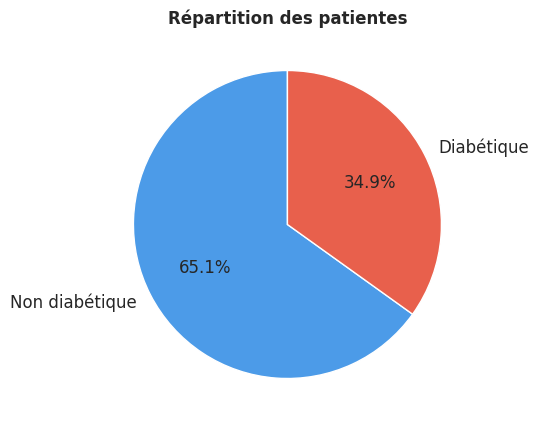

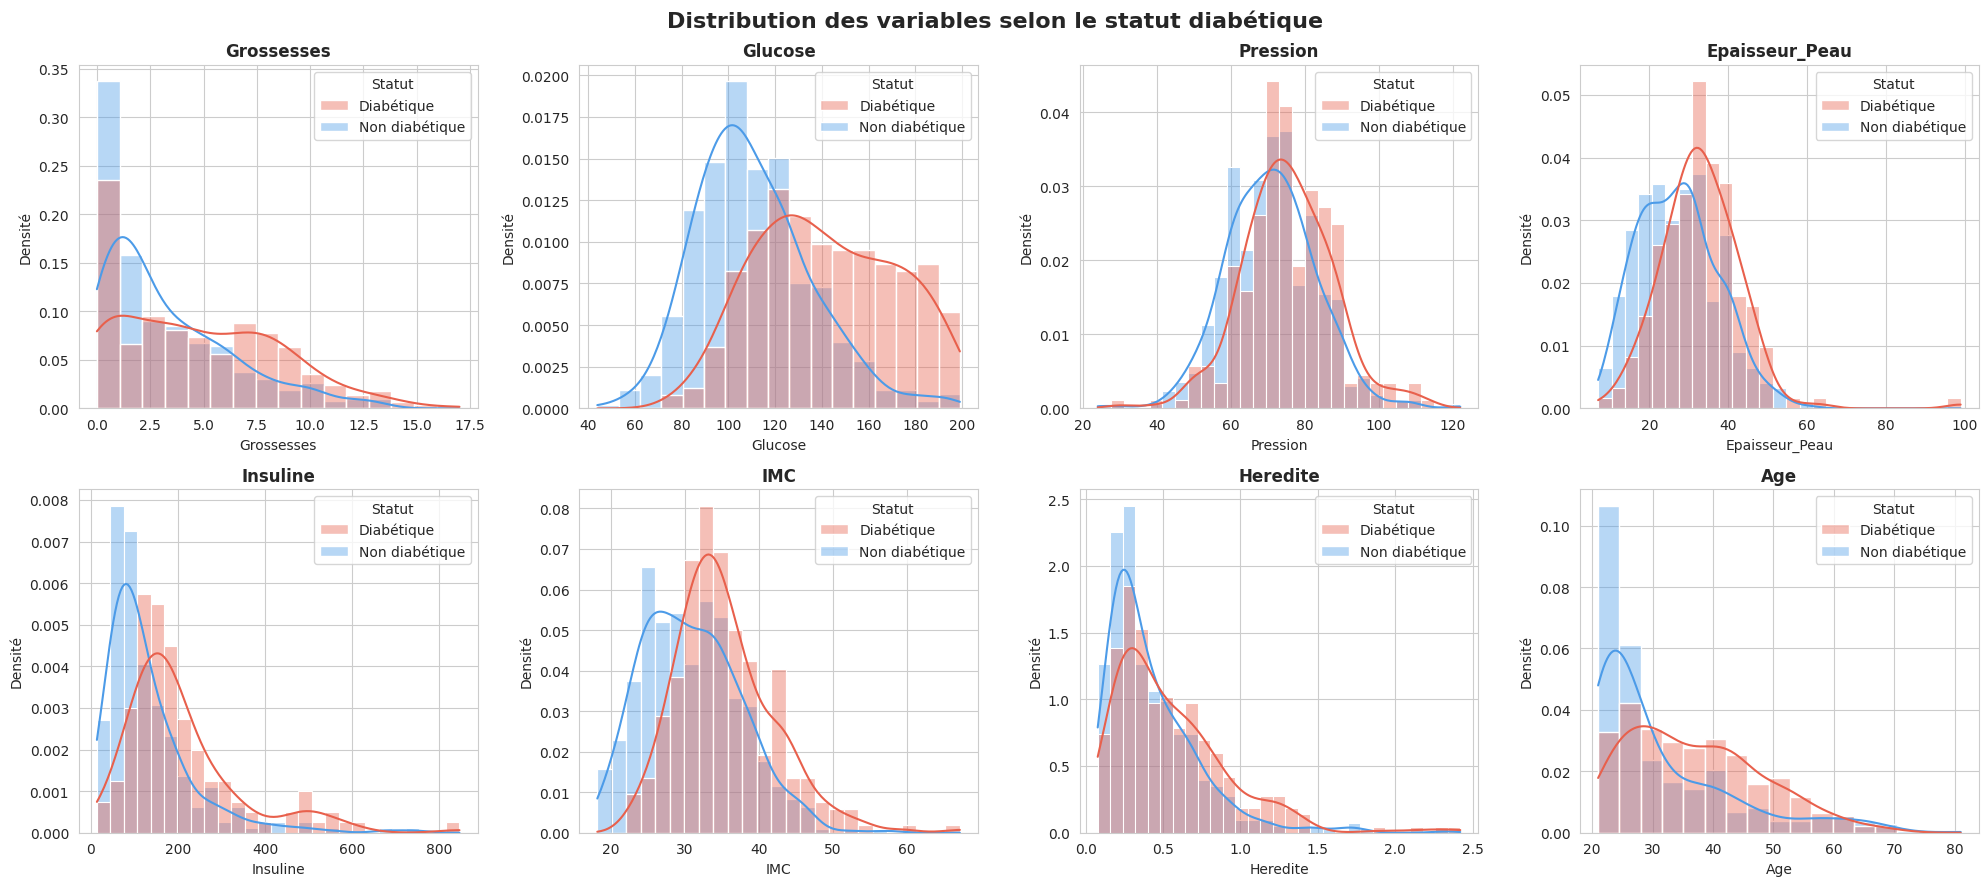

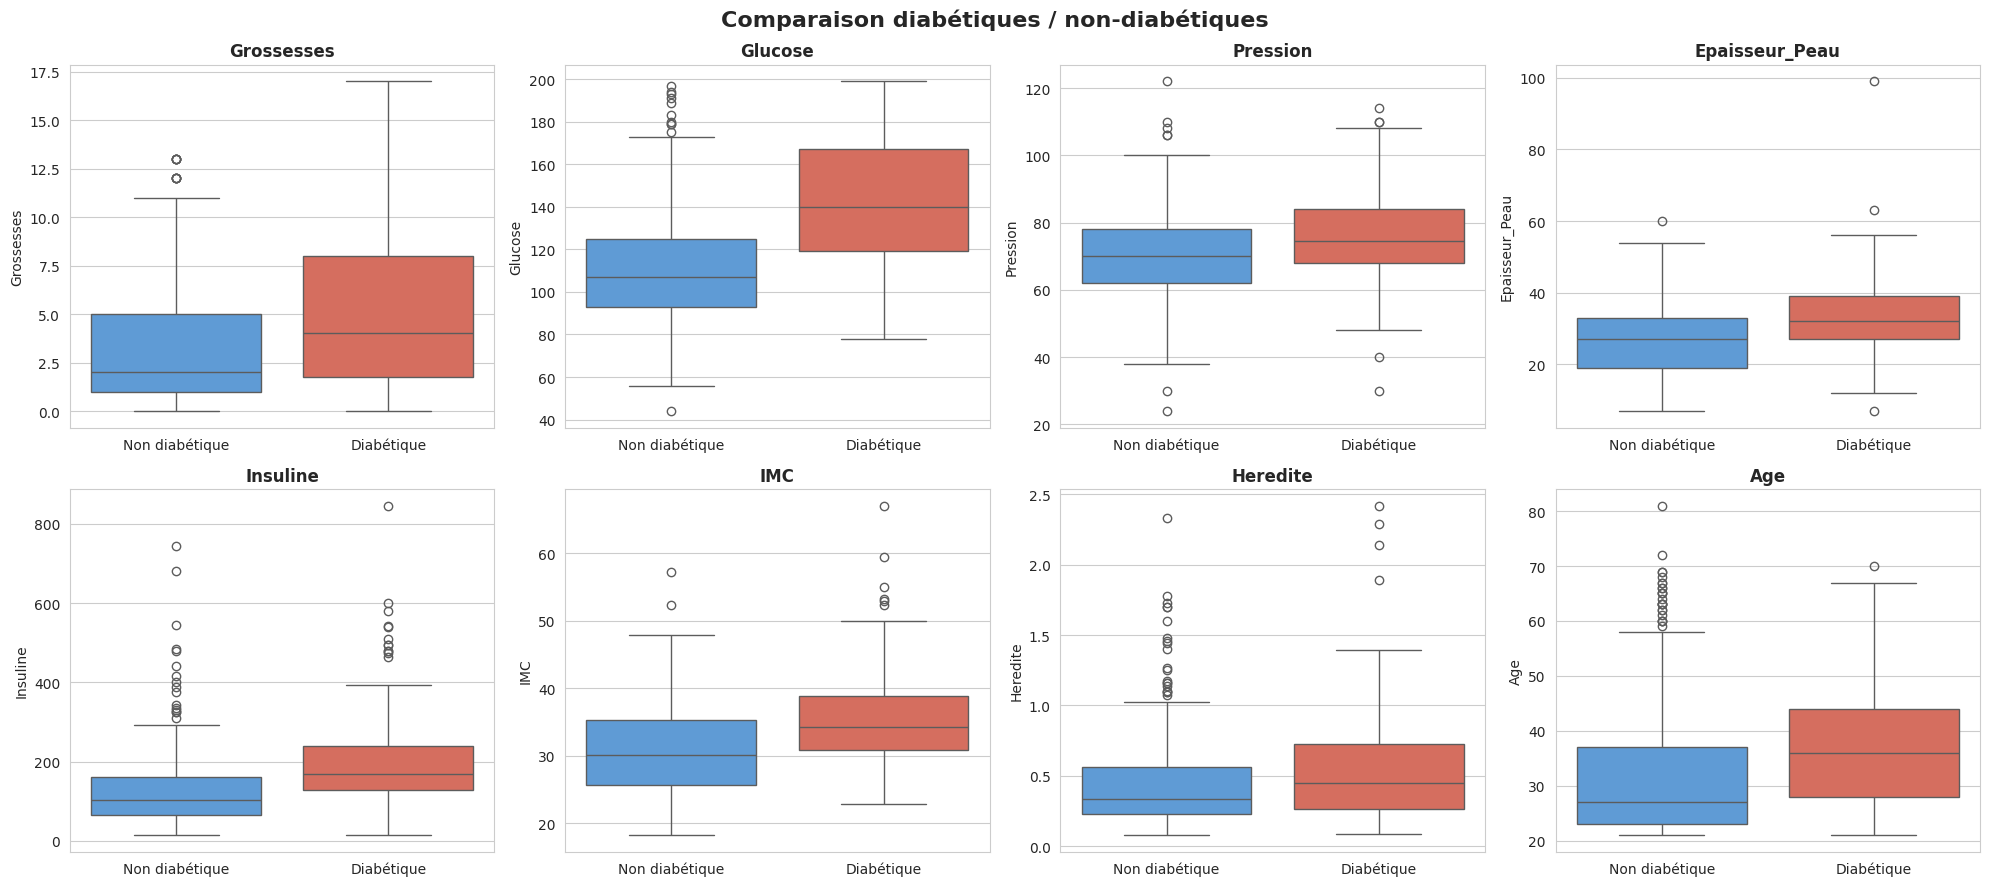

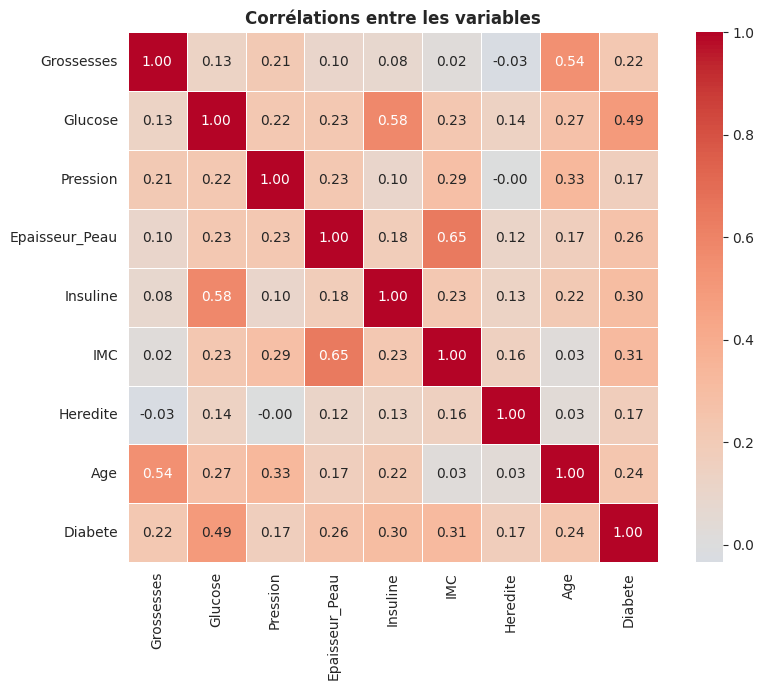

=== CORRÉLATION AVEC LE DIABÈTE (de la plus forte à la plus faible) ===
Glucose           0.49
IMC               0.31
Insuline          0.30
Epaisseur_Peau    0.26
Age               0.24
Grossesses        0.22
Heredite          0.17
Pression          0.17
Name: Diabete, dtype: float64


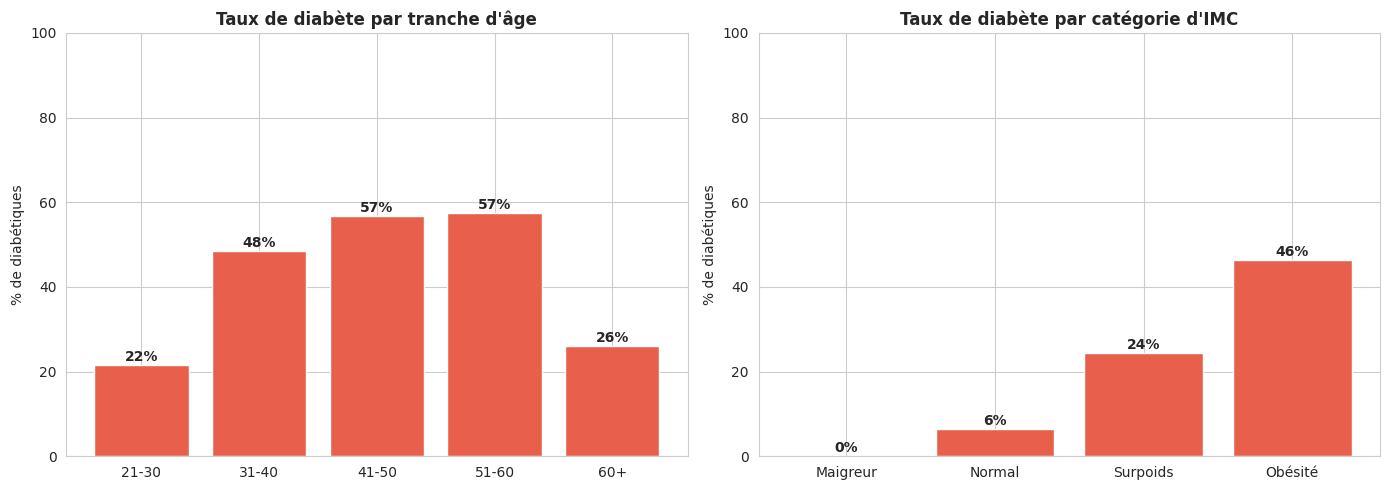

In [4]:
# ============================================
# ÉTAPE 3 : VISUALISATIONS MÉDICALES
# ============================================

sns.set_style("whitegrid")
couleurs = {'Non diabétique': '#4C9BE8', 'Diabétique': '#E8604C'}
ordre = ['Non diabétique', 'Diabétique']

df_viz = df_propre.copy()
df_viz['Statut'] = df_viz['Diabete'].map({0: 'Non diabétique', 1: 'Diabétique'})

variables = ['Grossesses', 'Glucose', 'Pression', 'Epaisseur_Peau',
             'Insuline', 'IMC', 'Heredite', 'Age']

# ---------- GRAPHIQUE 1 : Répartition des patientes ----------
plt.figure(figsize=(5, 5))
compte = df_viz['Statut'].value_counts()
plt.pie(compte.values, labels=compte.index, autopct='%1.1f%%',
        colors=[couleurs[s] for s in compte.index],
        startangle=90, textprops={'fontsize': 12})
plt.title("Répartition des patientes", fontweight='bold')
plt.savefig('01_repartition.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- GRAPHIQUE 2 : Distribution de chaque variable ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, var in zip(axes.flatten(), variables):
    sns.histplot(data=df_viz, x=var, hue='Statut', palette=couleurs,
                 kde=True, stat='density', common_norm=False,
                 alpha=0.4, ax=ax)
    ax.set_title(var, fontweight='bold')
    ax.set_ylabel('Densité')
fig.suptitle("Distribution des variables selon le statut diabétique",
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('02_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- GRAPHIQUE 3 : Boxplots (valeurs extrêmes) ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, var in zip(axes.flatten(), variables):
    sns.boxplot(data=df_viz, x='Statut', y=var, hue='Statut',
                order=ordre, hue_order=ordre, palette=couleurs,
                legend=False, ax=ax)
    ax.set_title(var, fontweight='bold')
    ax.set_xlabel('')
fig.suptitle("Comparaison diabétiques / non-diabétiques",
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('03_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- GRAPHIQUE 4 : Corrélations ----------
plt.figure(figsize=(9, 7))
corr = df_propre.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title("Corrélations entre les variables", fontweight='bold')
plt.tight_layout()
plt.savefig('04_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

print("=== CORRÉLATION AVEC LE DIABÈTE (de la plus forte à la plus faible) ===")
print(corr['Diabete'].drop('Diabete').sort_values(ascending=False).round(2))

# ---------- GRAPHIQUE 5 : Taux de diabète par âge et par IMC ----------
df_viz['Tranche_Age'] = pd.cut(df_viz['Age'],
                               bins=[20, 30, 40, 50, 60, 100],
                               labels=['21-30', '31-40', '41-50', '51-60', '60+'])
df_viz['Categorie_IMC'] = pd.cut(df_viz['IMC'],
                                 bins=[0, 18.5, 25, 30, 100],
                                 labels=['Maigreur', 'Normal', 'Surpoids', 'Obésité'])

taux_age = df_viz.groupby('Tranche_Age', observed=True)['Diabete'].mean() * 100
taux_imc = df_viz.groupby('Categorie_IMC', observed=True)['Diabete'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, taux, titre in zip(axes, [taux_age, taux_imc],
                           ["Taux de diabète par tranche d'âge",
                            "Taux de diabète par catégorie d'IMC"]):
    barres = ax.bar(taux.index.astype(str), taux.values, color='#E8604C')
    for barre, valeur in zip(barres, taux.values):
        ax.text(barre.get_x() + barre.get_width() / 2, valeur + 1,
                f"{valeur:.0f}%", ha='center', fontweight='bold')
    ax.set_title(titre, fontweight='bold')
    ax.set_ylabel("% de diabétiques")
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig('05_taux_age_imc.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
print(df_viz['Tranche_Age'].value_counts().sort_index())
print()
print(df_viz['Categorie_IMC'].value_counts().sort_index())

Tranche_Age
21-30    417
31-40    157
41-50    113
51-60     54
60+       27
Name: count, dtype: int64

Categorie_IMC
Maigreur      4
Normal      108
Surpoids    180
Obésité     465
Name: count, dtype: int64


Entraînement : 614 patientes (34.9% diabétiques)
Test         : 154 patientes (35.1% diabétiques)

=== COMPARAISON DES MODÈLES (triés par Recall sur le test) ===
                            Accuracy_train  Accuracy_test  Précision  \
Modèle                                                                 
XGBoost                              0.915          0.760      0.639   
Random Forest                        0.881          0.734      0.600   
Régression Logistique                0.759          0.734      0.603   
Référence (toujours "non")           0.651          0.649      0.000   

                            Recall_test  Recall_CV     F1  
Modèle                                                     
XGBoost                           0.722      0.682  0.678  
Random Forest                     0.722      0.724  0.655  
Régression Logistique             0.704      0.701  0.650  
Référence (toujours "non")        0.000      0.000  0.000  


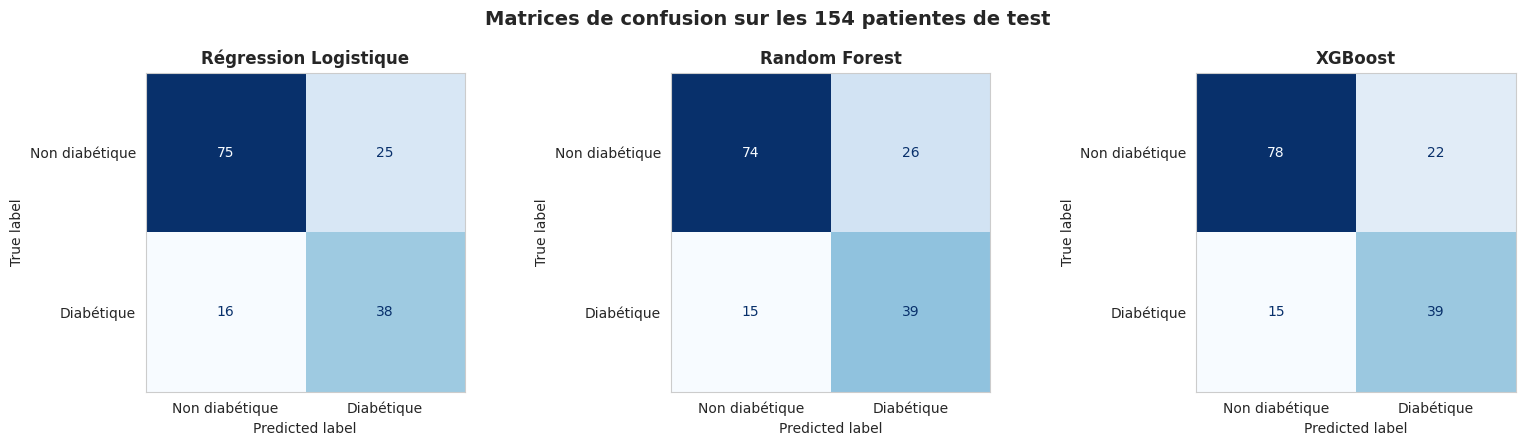

In [6]:
# ============================================
# ÉTAPE 4 : MODÈLES DE MACHINE LEARNING
# ============================================

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

# ---------- 1. SÉPARATION TRAIN / TEST ----------
X = df_propre.drop('Diabete', axis=1)
y = df_propre['Diabete']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entraînement : {len(X_train)} patientes ({y_train.mean()*100:.1f}% diabétiques)")
print(f"Test         : {len(X_test)} patientes ({y_test.mean()*100:.1f}% diabétiques)")

# Poids pour compenser le déséquilibre (utilisé par XGBoost)
poids = (y_train == 0).sum() / (y_train == 1).sum()

# ---------- 2. LES MODÈLES (chacun avec son imputation par la médiane) ----------
modeles = {
    'Référence (toujours "non")': Pipeline([
        ('imputation', SimpleImputer(strategy='median')),
        ('modele', DummyClassifier(strategy='most_frequent'))]),

    'Régression Logistique': Pipeline([
        ('imputation', SimpleImputer(strategy='median')),
        ('standardisation', StandardScaler()),
        ('modele', LogisticRegression(max_iter=1000, class_weight='balanced',
                                      random_state=42))]),

    'Random Forest': Pipeline([
        ('imputation', SimpleImputer(strategy='median')),
        ('modele', RandomForestClassifier(n_estimators=300, max_depth=6,
                                          class_weight='balanced',
                                          random_state=42))]),

    'XGBoost': Pipeline([
        ('imputation', SimpleImputer(strategy='median')),
        ('modele', XGBClassifier(n_estimators=300, learning_rate=0.05,
                                 max_depth=3, scale_pos_weight=poids,
                                 eval_metric='logloss', random_state=42))]),
}

# ---------- 3. ENTRAÎNEMENT ET ÉVALUATION ----------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats = []

for nom, modele in modeles.items():
    # Recall moyen sur 5 découpages de l'entraînement (plus fiable qu'un seul test)
    recall_cv = cross_val_score(modele, X_train, y_train, cv=cv, scoring='recall').mean()

    modele.fit(X_train, y_train)
    pred_train = modele.predict(X_train)
    pred_test = modele.predict(X_test)

    resultats.append({
        'Modèle': nom,
        'Accuracy_train': accuracy_score(y_train, pred_train),
        'Accuracy_test': accuracy_score(y_test, pred_test),
        'Précision': precision_score(y_test, pred_test, zero_division=0),
        'Recall_test': recall_score(y_test, pred_test),
        'Recall_CV': recall_cv,
        'F1': f1_score(y_test, pred_test, zero_division=0),
    })

tableau = pd.DataFrame(resultats).set_index('Modèle').round(3)
print("\n=== COMPARAISON DES MODÈLES (triés par Recall sur le test) ===")
print(tableau.sort_values('Recall_test', ascending=False))

# ---------- 4. MATRICES DE CONFUSION ----------
vrais_modeles = ['Régression Logistique', 'Random Forest', 'XGBoost']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, nom in zip(axes, vrais_modeles):
    ConfusionMatrixDisplay.from_estimator(
        modeles[nom], X_test, y_test,
        display_labels=['Non diabétique', 'Diabétique'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nom, fontweight='bold')
    ax.grid(False)
fig.suptitle("Matrices de confusion sur les 154 patientes de test",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('06_matrices_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

=== MEILLEURS RÉGLAGES ===
{'modele__learning_rate': 0.03, 'modele__max_depth': 2, 'modele__min_child_weight': 5, 'modele__n_estimators': 100}
AUC en validation croisée : 0.840
AUC Régression Logistique (pour comparer) : 0.844

=== EFFET DU SEUIL (validation croisée sur l'entraînement) ===
       Recall  Précision     F1
Seuil                          
0.20    0.981      0.429  0.597
0.25    0.949      0.443  0.604
0.30    0.925      0.486  0.638
0.35    0.897      0.530  0.667
0.40    0.864      0.566  0.684
0.45    0.813      0.613  0.699
0.50    0.762      0.639  0.695
0.55    0.682      0.667  0.674
0.60    0.617      0.698  0.655
0.65    0.528      0.715  0.608
0.70    0.444      0.779  0.565
0.75    0.336      0.791  0.472
0.80    0.280      0.870  0.424

>>> Seuil choisi : 0.45

=== RÉSULTAT FINAL SUR LES 154 PATIENTES DE TEST ===
AUC test : 0.816
                precision    recall  f1-score   support

Non diabétique       0.89      0.70      0.78       100
    Diabétique      

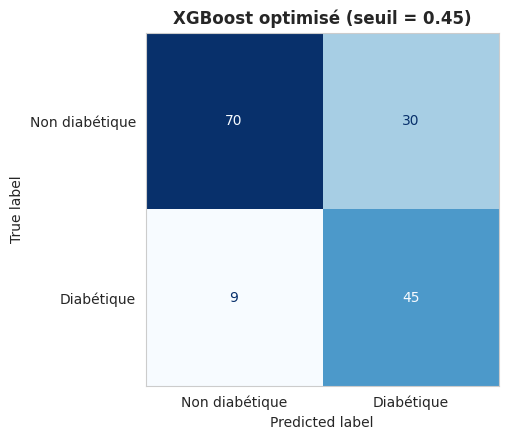

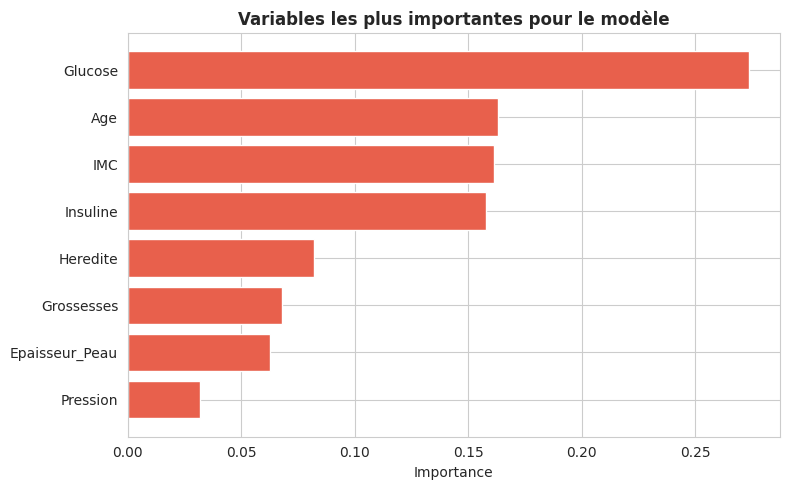


Modèle sauvegardé : modele_diabete.joblib


In [7]:
# ============================================
# ÉTAPE 5 : OPTIMISATION ET CHOIX DU SEUIL
# ============================================

from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import roc_auc_score, classification_report
import joblib

# ---------- 1. RÉGLAGE DE XGBOOST ----------
pipeline_xgb = Pipeline([
    ('imputation', SimpleImputer(strategy='median')),
    ('modele', XGBClassifier(scale_pos_weight=poids, subsample=0.8,
                             colsample_bytree=0.8, eval_metric='logloss',
                             random_state=42))])

grille = {
    'modele__n_estimators': [100, 200, 300],
    'modele__max_depth': [2, 3, 4],
    'modele__learning_rate': [0.03, 0.1],
    'modele__min_child_weight': [1, 5],
}

recherche = GridSearchCV(pipeline_xgb, grille, scoring='roc_auc',
                         cv=cv, n_jobs=-1)
recherche.fit(X_train, y_train)
meilleur = recherche.best_estimator_

print("=== MEILLEURS RÉGLAGES ===")
print(recherche.best_params_)
print(f"AUC en validation croisée : {recherche.best_score_:.3f}")

auc_lr = cross_val_score(modeles['Régression Logistique'], X_train, y_train,
                         cv=cv, scoring='roc_auc').mean()
print(f"AUC Régression Logistique (pour comparer) : {auc_lr:.3f}")

# ---------- 2. CHOIX DU SEUIL (sur l'entraînement uniquement) ----------
proba_cv = cross_val_predict(meilleur, X_train, y_train, cv=cv,
                             method='predict_proba')[:, 1]

lignes = []
for seuil in np.arange(0.20, 0.81, 0.05):
    pred = (proba_cv >= seuil).astype(int)
    lignes.append({'Seuil': round(seuil, 2),
                   'Recall': recall_score(y_train, pred),
                   'Précision': precision_score(y_train, pred, zero_division=0),
                   'F1': f1_score(y_train, pred, zero_division=0)})
tableau_seuils = pd.DataFrame(lignes).set_index('Seuil').round(3)

print("\n=== EFFET DU SEUIL (validation croisée sur l'entraînement) ===")
print(tableau_seuils)

# Objectif médical : détecter au moins 80 % des diabétiques,
# avec le seuil le plus élevé possible (donc le moins de fausses alertes)
objectif_recall = 0.80
candidats = tableau_seuils[tableau_seuils['Recall'] >= objectif_recall]
seuil_choisi = candidats.index.max() if len(candidats) else tableau_seuils['Recall'].idxmax()
print(f"\n>>> Seuil choisi : {seuil_choisi}")

# ---------- 3. ÉVALUATION FINALE SUR LE TEST (une seule fois) ----------
proba_test = meilleur.predict_proba(X_test)[:, 1]
pred_final = (proba_test >= seuil_choisi).astype(int)

print(f"\n=== RÉSULTAT FINAL SUR LES 154 PATIENTES DE TEST ===")
print(f"AUC test : {roc_auc_score(y_test, proba_test):.3f}")
print(classification_report(y_test, pred_final,
                            target_names=['Non diabétique', 'Diabétique']))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_final, display_labels=['Non diabétique', 'Diabétique'],
    cmap='Blues', colorbar=False, ax=ax)
ax.set_title(f"XGBoost optimisé (seuil = {seuil_choisi})", fontweight='bold')
ax.grid(False)
plt.tight_layout()
plt.savefig('07_matrice_finale.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- 4. IMPORTANCE DES VARIABLES ----------
importances = pd.Series(meilleur.named_steps['modele'].feature_importances_,
                        index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(importances.index, importances.values, color='#E8604C')
plt.title("Variables les plus importantes pour le modèle", fontweight='bold')
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig('08_importance_variables.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- 5. SAUVEGARDE POUR L'API FASTAPI ----------
joblib.dump({'modele': meilleur,
             'seuil': float(seuil_choisi),
             'colonnes': list(X.columns)}, 'modele_diabete.joblib')
print("\nModèle sauvegardé : modele_diabete.joblib")

In [8]:
# ============================================
# EXPORT DES FICHIERS DU PROJET
# ============================================
import zipfile, glob
import sklearn, xgboost
from google.colab import files

# 1. Versions à utiliser dans requirements.txt
print("=== VERSIONS (à copier dans requirements.txt) ===")
print(f"scikit-learn=={sklearn.__version__}")
print(f"xgboost=={xgboost.__version__}")
print(f"pandas=={pd.__version__}")
print(f"numpy=={np.__version__}")
print(f"joblib=={joblib.__version__}")

# 2. Archive avec le modèle et toutes les images
fichiers = glob.glob('*.png') + ['modele_diabete.joblib']
with zipfile.ZipFile('fichiers_projet_diabete.zip', 'w') as z:
    for f in fichiers:
        z.write(f)
print("\nFichiers archivés :", fichiers)

# 3. Téléchargement
files.download('fichiers_projet_diabete.zip')

=== VERSIONS (à copier dans requirements.txt) ===
scikit-learn==1.6.1
xgboost==3.4.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0

Fichiers archivés : ['04_correlations.png', '02_distributions.png', '08_importance_variables.png', '05_taux_age_imc.png', '03_boxplots.png', '06_matrices_confusion.png', '01_repartition.png', '07_matrice_finale.png', 'modele_diabete.joblib']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>